In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

print("Everything is working!")

Everything is working!


In [2]:
df = pd.read_csv("Walmart.csv")

In [3]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 402.3 KB


In [5]:
df.shape

(6435, 8)

In [6]:
df.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

In [7]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [8]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

In [9]:
df = df.sort_values("Date")

In [10]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1287,10,2010-02-05,2193048.75,0,54.34,2.962,126.442065,9.765
5148,37,2010-02-05,536006.73,0,45.97,2.572,209.852966,8.554
2288,17,2010-02-05,789036.02,0,23.11,2.666,126.442065,6.548
4147,30,2010-02-05,465108.52,0,39.05,2.572,210.752605,8.324


In [11]:
df["Year"] = df["Date"].dt.year

In [12]:
df["Month"] = df["Date"].dt.month

In [13]:
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)

In [14]:
df["Time_Index"] = np.arange(len(df))

In [15]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week,Time_Index
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106,2010,2,5,0
1287,10,2010-02-05,2193048.75,0,54.34,2.962,126.442065,9.765,2010,2,5,1
5148,37,2010-02-05,536006.73,0,45.97,2.572,209.852966,8.554,2010,2,5,2
2288,17,2010-02-05,789036.02,0,23.11,2.666,126.442065,6.548,2010,2,5,3
4147,30,2010-02-05,465108.52,0,39.05,2.572,210.752605,8.324,2010,2,5,4


In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 6435 entries, 0 to 6434
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[us]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
 8   Year          6435 non-null   int32         
 9   Month         6435 non-null   int32         
 10  Week          6435 non-null   int64         
 11  Time_Index    6435 non-null   int64         
dtypes: datetime64[us](1), float64(5), int32(2), int64(4)
memory usage: 603.3 KB


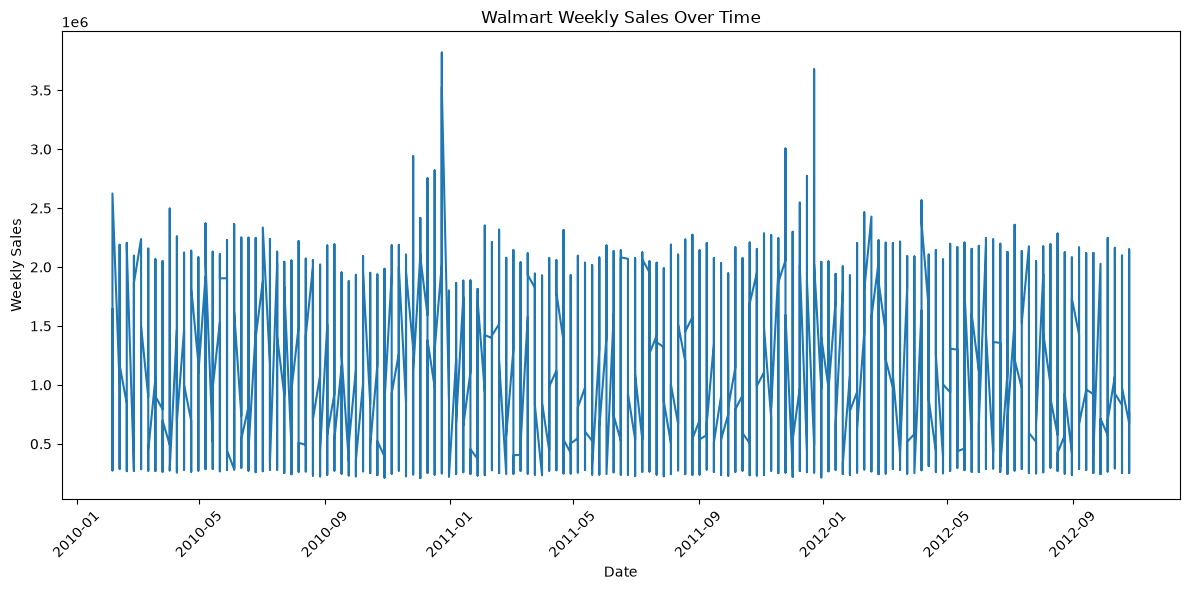

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(df["Date"], df["Weekly_Sales"])

plt.title("Walmart Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
store_sales = df.groupby("Store")["Weekly_Sales"].mean()

store_sales

Store
1     1.555264e+06
2     1.925751e+06
3     4.027044e+05
4     2.094713e+06
5     3.180118e+05
6     1.564728e+06
7     5.706173e+05
8     9.087495e+05
9     5.439806e+05
10    1.899425e+06
11    1.356383e+06
12    1.009002e+06
13    2.003620e+06
14    2.020978e+06
15    6.233125e+05
16    5.192477e+05
17    8.935814e+05
18    1.084718e+06
19    1.444999e+06
20    2.107677e+06
21    7.560691e+05
22    1.028501e+06
23    1.389864e+06
24    1.356755e+06
25    7.067215e+05
26    1.002912e+06
27    1.775216e+06
28    1.323522e+06
29    5.394514e+05
30    4.385796e+05
31    1.395901e+06
32    1.166568e+06
33    2.598617e+05
34    9.667816e+05
35    9.197250e+05
36    3.735120e+05
37    5.189003e+05
38    3.857317e+05
39    1.450668e+06
40    9.641280e+05
41    1.268125e+06
42    5.564039e+05
43    6.333247e+05
44    3.027489e+05
45    7.859814e+05
Name: Weekly_Sales, dtype: float64

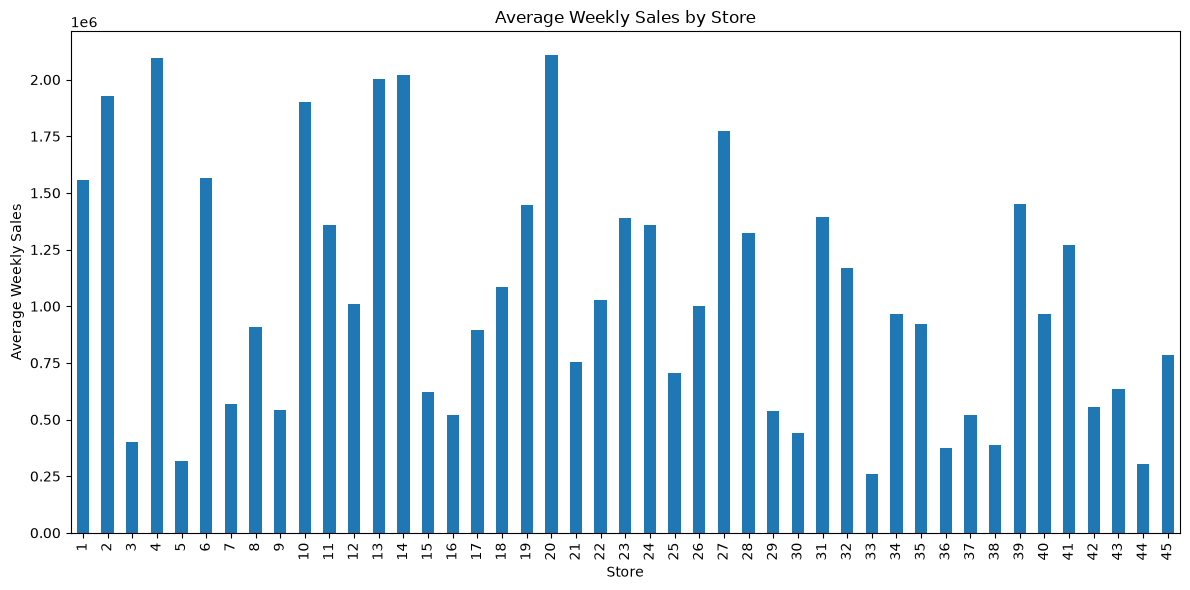

In [19]:
plt.figure(figsize=(12, 6))

store_sales.plot(kind="bar")

plt.title("Average Weekly Sales by Store")
plt.xlabel("Store")
plt.ylabel("Average Weekly Sales")

plt.tight_layout()
plt.show()

In [20]:
holiday_sales = df.groupby("Holiday_Flag")["Weekly_Sales"].mean()

holiday_sales

Holiday_Flag
0    1.041256e+06
1    1.122888e+06
Name: Weekly_Sales, dtype: float64

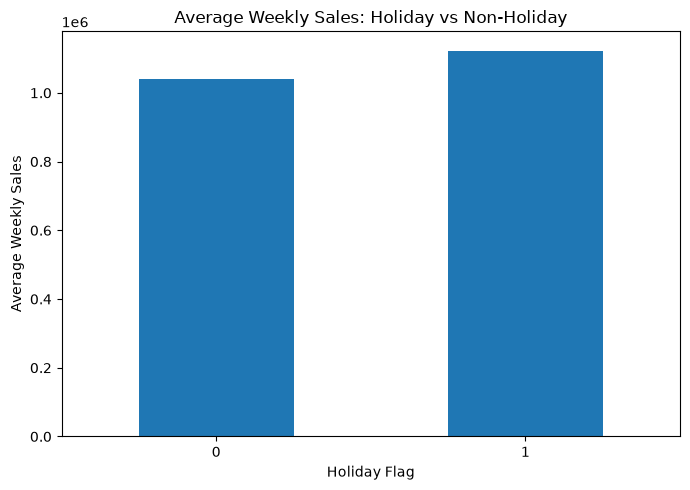

In [21]:
plt.figure(figsize=(7, 5))

holiday_sales.plot(kind="bar")

plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.xlabel("Holiday Flag")
plt.ylabel("Average Weekly Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [23]:
features = [
    "Store",
    "Holiday_Flag",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment",
    "Year",
    "Month",
    "Week",
    "Time_Index"
]

X = df[features]
y = df["Weekly_Sales"]

In [24]:
X.head()

,Store,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week,Time_Index
0,1,0,42.31,2.572,211.096358,8.106,2010,2,5,0
1287,10,0,54.34,2.962,126.442065,9.765,2010,2,5,1
5148,37,0,45.97,2.572,209.852966,8.554,2010,2,5,2
2288,17,0,23.11,2.666,126.442065,6.548,2010,2,5,3
4147,30,0,39.05,2.572,210.752605,8.324,2010,2,5,4


In [25]:
y.head()

0       1643690.90
1287    2193048.75
5148     536006.73
2288     789036.02
4147     465108.52
Name: Weekly_Sales, dtype: float64

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [27]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5148, 10)
Testing data: (1287, 10)


In [28]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [29]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print(y_pred[:10])

Predictions completed!
[1041252.09601128  933417.28849232 1151644.50225073  962776.76395237
 1004128.53699321 1067079.13611794 1229202.00691628  993434.70353264
 1309467.77313679 1210736.40592957]


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("------------------")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

Model Performance
------------------
MAE  : 434402.07964283536
MSE  : 268337889023.45242
RMSE : 518013.40621981246
R²   : 0.13922388704939148


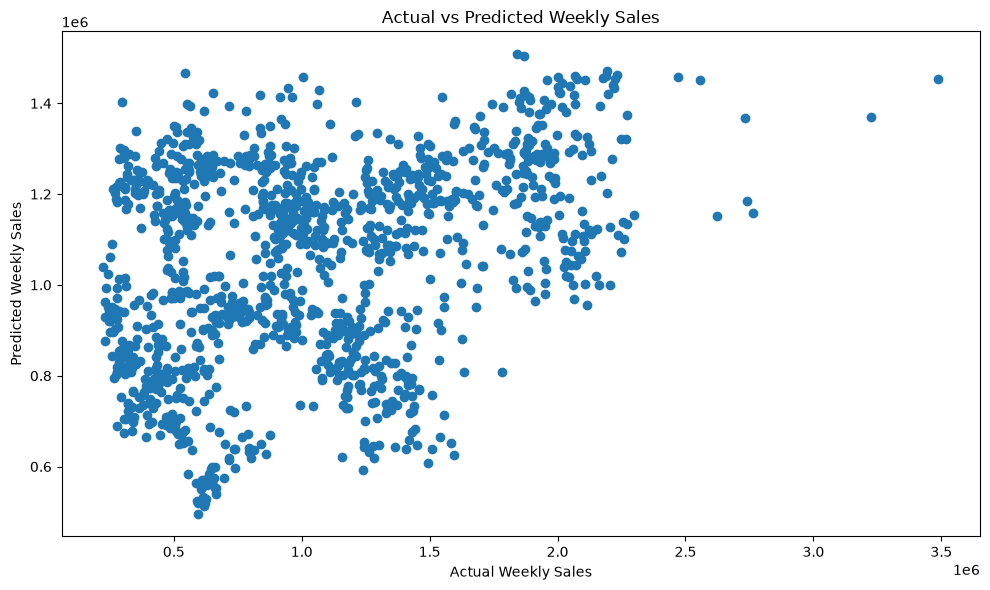

In [31]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")
plt.title("Actual vs Predicted Weekly Sales")

plt.tight_layout()
plt.show()

In [32]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

coefficients

,Feature,Coefficient
3,Fuel_Price,45820.472356
1,Holiday_Flag,44075.436734
7,Month,42289.251217
9,Time_Index,55.356416
2,Temperature,-2211.136181
4,CPI,-2237.011473
8,Week,-8704.064106
0,Store,-15341.704656
5,Unemployment,-21709.768552
6,Year,-153989.435711


In [33]:
coefficients

,Feature,Coefficient
3,Fuel_Price,45820.472356
1,Holiday_Flag,44075.436734
7,Month,42289.251217
9,Time_Index,55.356416
2,Temperature,-2211.136181
4,CPI,-2237.011473
8,Week,-8704.064106
0,Store,-15341.704656
5,Unemployment,-21709.768552
6,Year,-153989.435711


In [34]:
from sklearn.tree import DecisionTreeRegressor

In [35]:
dt_model = DecisionTreeRegressor(
    random_state=42
)

In [36]:
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [37]:
dt_pred = dt_model.predict(X_test)

print("Predictions completed!")
print(dt_pred[:10])

Predictions completed!
[1554651.08  274721.85  507297.88  688958.75 1635984.07 1213994.39
  403342.4   213538.32 2004831.14  452169.28]


In [38]:
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Performance")
print("-------------------------")
print("MAE  :", dt_mae)
print("MSE  :", dt_mse)
print("RMSE :", dt_rmse)
print("R²   :", dt_r2)

Decision Tree Performance
-------------------------
MAE  : 74118.78576534576
MSE  : 22754826675.971027
RMSE : 150847.0307164547
R²   : 0.9270069115908738


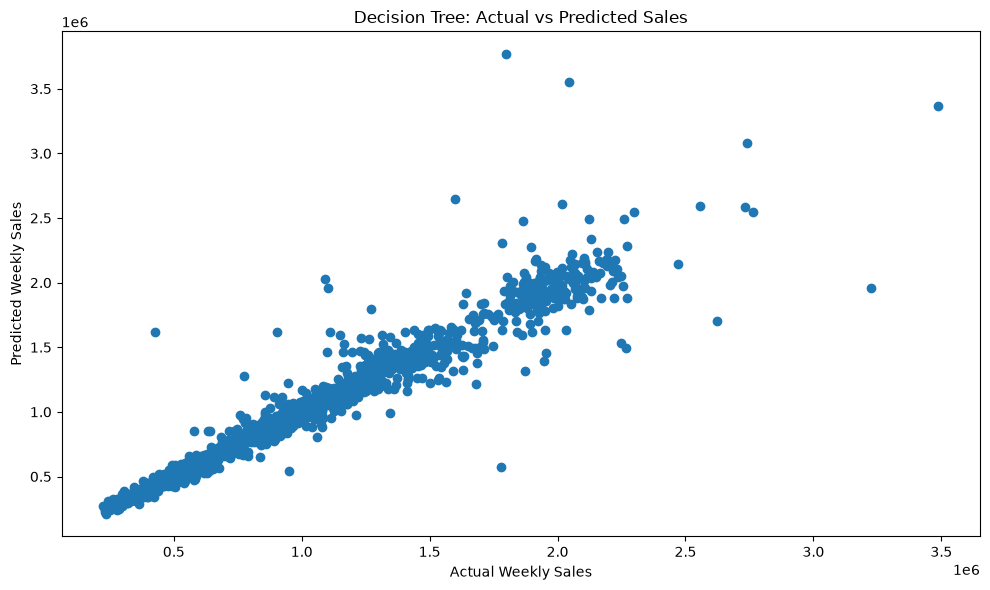

In [39]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, dt_pred)

plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")
plt.title("Decision Tree: Actual vs Predicted Sales")

plt.tight_layout()
plt.show()

In [40]:
dt_importance = pd.DataFrame({
    "Feature": features,
    "Importance": dt_model.feature_importances_
})

dt_importance = dt_importance.sort_values(
    by="Importance",
    ascending=False
)

dt_importance

,Feature,Importance
0,Store,0.630657
4,CPI,0.148396
5,Unemployment,0.130585
8,Week,0.054919
2,Temperature,0.016096
3,Fuel_Price,0.010965
9,Time_Index,0.004360
1,Holiday_Flag,0.002444
7,Month,0.001511
6,Year,0.000067


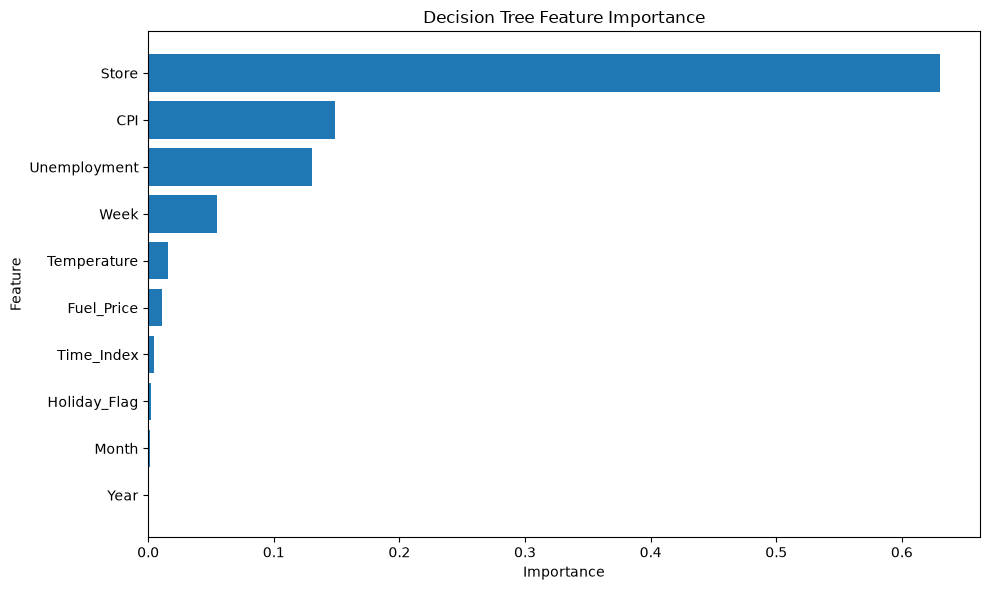

In [41]:
plt.figure(figsize=(10, 6))

plt.barh(
    dt_importance["Feature"],
    dt_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [42]:
from sklearn.ensemble import RandomForestRegressor

In [43]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [44]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [45]:
rf_pred = rf_model.predict(X_test)

print("Predictions completed!")
print(rf_pred[:10])

Predictions completed!
[1624517.0947  252481.1327  507226.284   690728.6417 1637065.6458
 1281540.6127  374335.7778  237957.2104 1926538.2611  464782.7826]


In [46]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Performance")
print("-------------------------")
print("MAE  :", rf_mae)
print("MSE  :", rf_mse)
print("RMSE :", rf_rmse)
print("R²   :", rf_r2)

Random Forest Performance
-------------------------
MAE  : 61160.10779463865
MSE  : 14992746357.318033
RMSE : 122444.87068602764
R²   : 0.9519061658460811


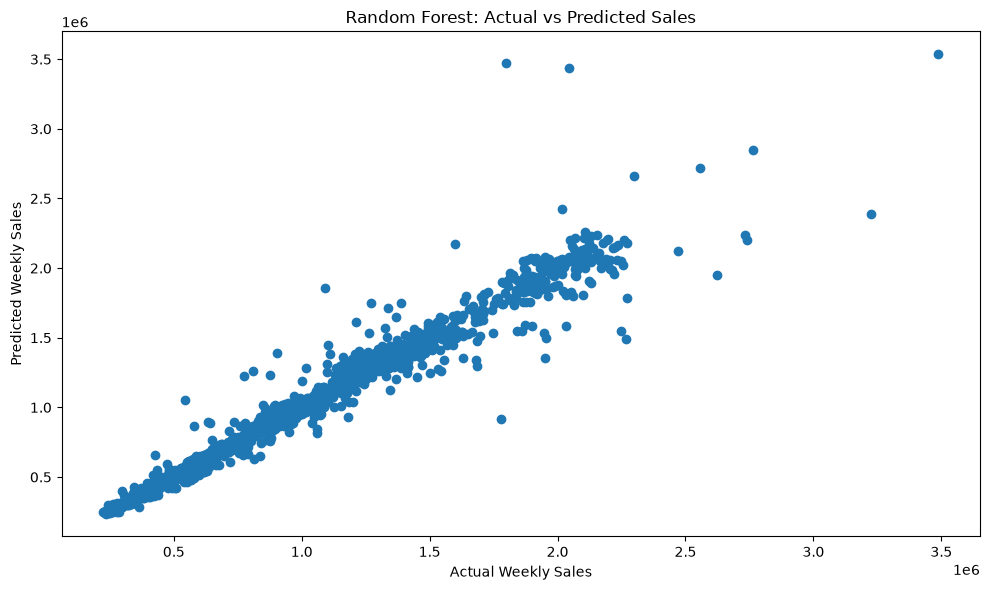

In [47]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, rf_pred)

plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")
plt.title("Random Forest: Actual vs Predicted Sales")

plt.tight_layout()
plt.show()

In [48]:
rf_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

rf_importance

,Feature,Importance
0,Store,0.669796
4,CPI,0.152954
5,Unemployment,0.092580
8,Week,0.051464
2,Temperature,0.013297
3,Fuel_Price,0.009773
9,Time_Index,0.005702
7,Month,0.002756
1,Holiday_Flag,0.001425
6,Year,0.000253


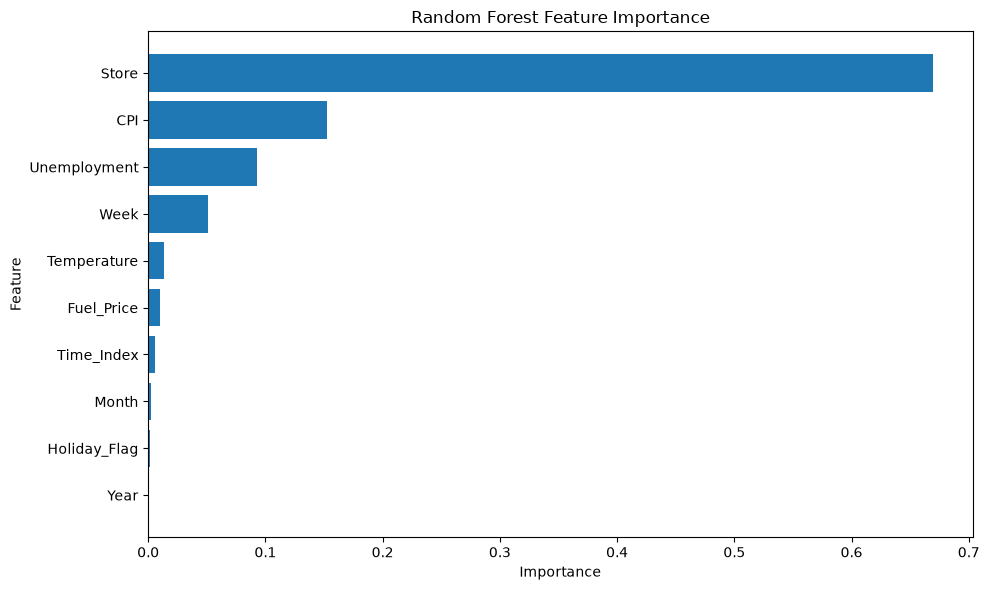

In [49]:
plt.figure(figsize=(10, 6))

plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [50]:
from sklearn.ensemble import GradientBoostingRegressor

In [51]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

In [52]:
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [53]:
gb_pred = gb_model.predict(X_test)

print("Predictions completed!")
print(gb_pred[:10])

Predictions completed!
[1503629.04556179  391668.78505099  675084.03691244  885153.57428297
 1505813.6551485  1219120.31204805  417035.36442947  492993.19437599
 1799731.27504009  663501.7219667 ]


In [54]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Performance")
print("----------------------------")
print("MAE  :", gb_mae)
print("MSE  :", gb_mse)
print("RMSE :", gb_rmse)
print("R²   :", gb_r2)

Gradient Boosting Performance
----------------------------
MAE  : 129422.38831196785
MSE  : 29102474021.533947
RMSE : 170594.4724237393
R²   : 0.906644885086233


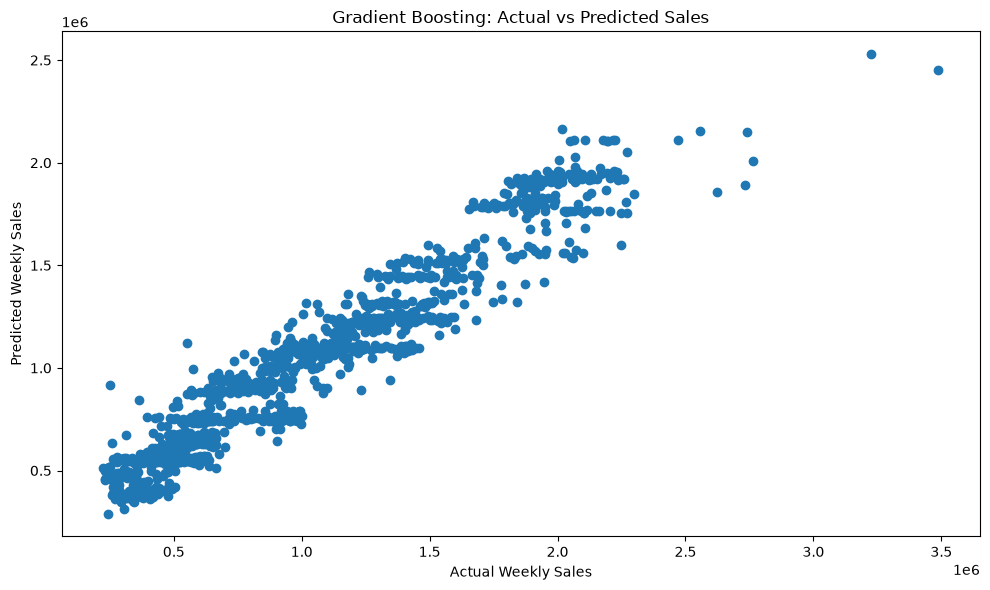

In [55]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, gb_pred)

plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")
plt.title("Gradient Boosting: Actual vs Predicted Sales")

plt.tight_layout()
plt.show()

In [56]:
gb_importance = pd.DataFrame({
    "Feature": features,
    "Importance": gb_model.feature_importances_
})

gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
)

gb_importance

,Feature,Importance
0,Store,0.745762
4,CPI,0.139443
5,Unemployment,0.060613
8,Week,0.043756
2,Temperature,0.004626
1,Holiday_Flag,0.002551
7,Month,0.001743
9,Time_Index,0.001081
3,Fuel_Price,0.000303
6,Year,0.000122


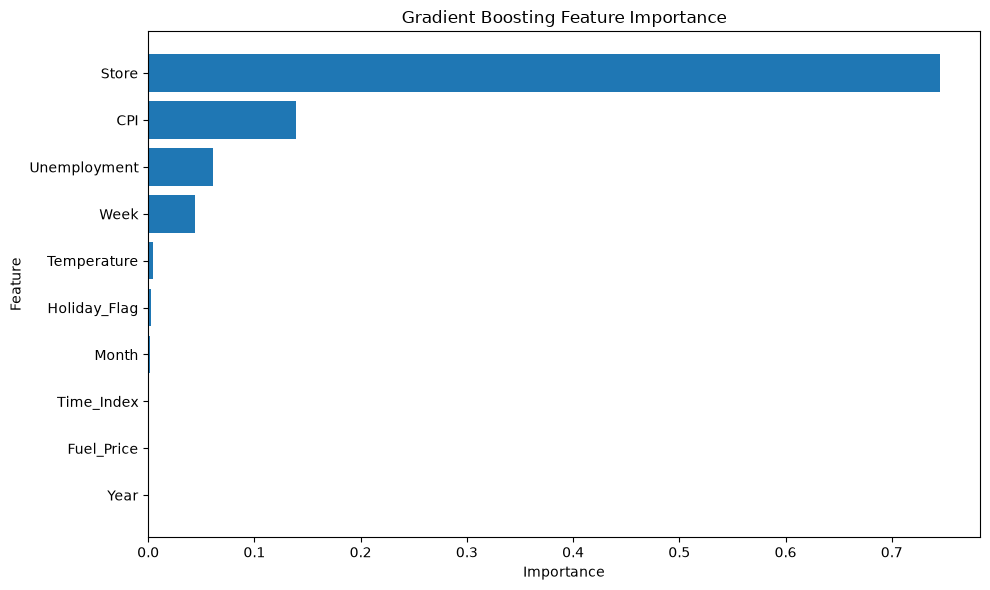

In [57]:
plt.figure(figsize=(10, 6))

plt.barh(
    gb_importance["Feature"],
    gb_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [58]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae,
        dt_mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        rmse,
        dt_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2": [
        r2,
        dt_r2,
        rf_r2,
        gb_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,434402.079643,518013.406220,0.139224
1,Decision Tree,74118.785765,150847.030716,0.927007
2,Random Forest,61160.107795,122444.870686,0.951906
3,Gradient Boosting,129422.388312,170594.472424,0.906645


In [59]:
comparison_rounded = comparison.copy()

comparison_rounded["MAE"] = comparison_rounded["MAE"].round(2)
comparison_rounded["RMSE"] = comparison_rounded["RMSE"].round(2)
comparison_rounded["R2"] = comparison_rounded["R2"].round(4)

comparison_rounded

,Model,MAE,RMSE,R2
0,Linear Regression,434402.08,518013.41,0.1392
1,Decision Tree,74118.79,150847.03,0.9270
2,Random Forest,61160.11,122444.87,0.9519
3,Gradient Boosting,129422.39,170594.47,0.9066


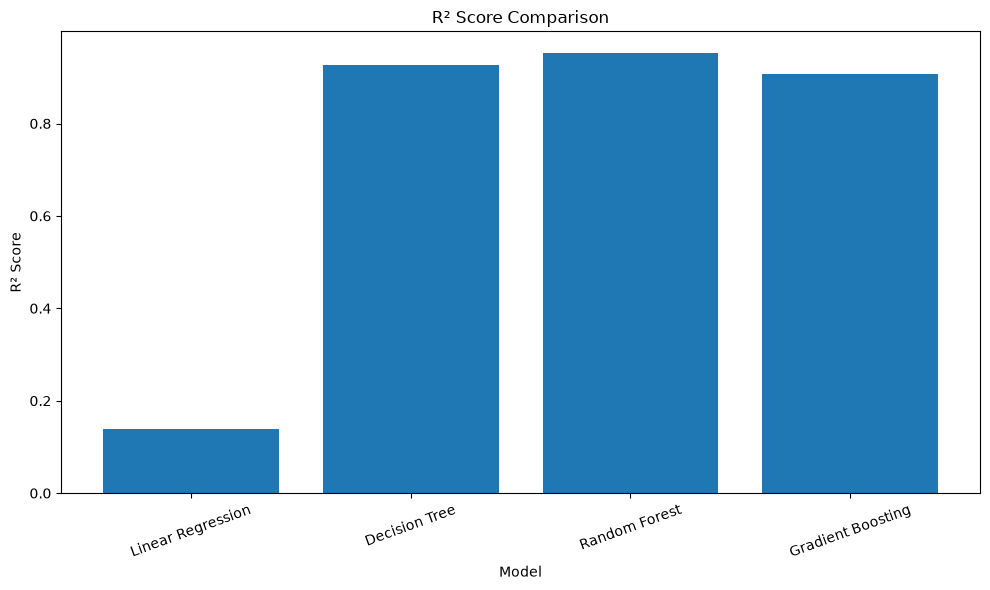

In [60]:
plt.figure(figsize=(10, 6))

plt.bar(comparison["Model"], comparison["R2"])

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("R² Score Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

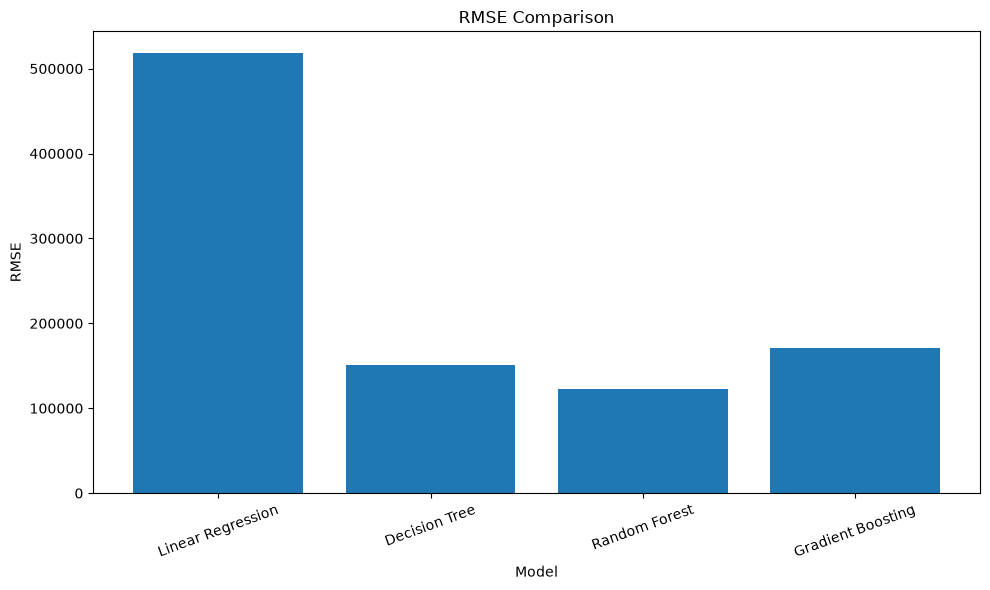

In [61]:
plt.figure(figsize=(10, 6))

plt.bar(comparison["Model"], comparison["RMSE"])

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("RMSE Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

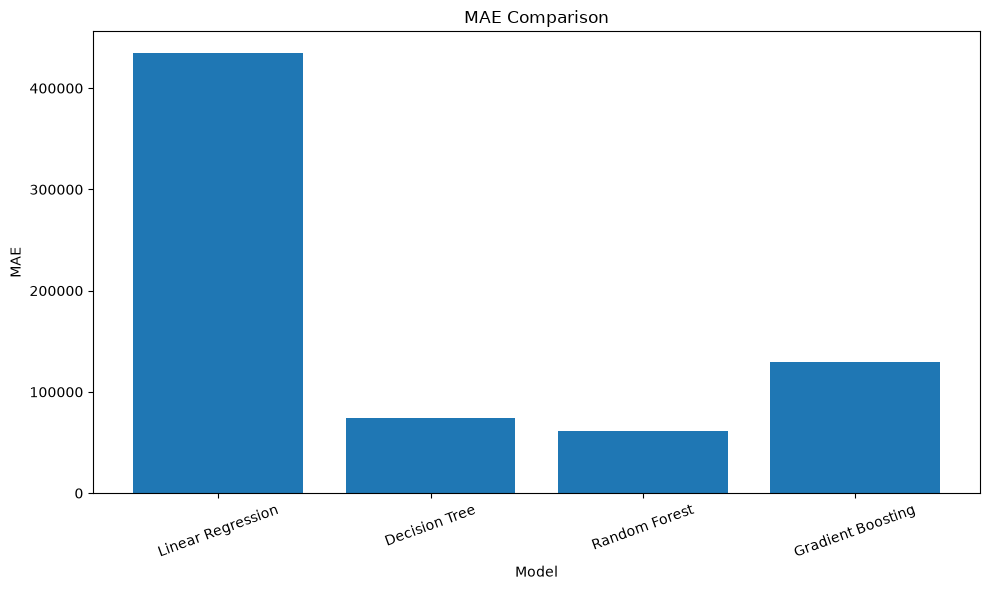

In [62]:
plt.figure(figsize=(10, 6))

plt.bar(comparison["Model"], comparison["MAE"])

plt.xlabel("Model")
plt.ylabel("MAE")
plt.title("MAE Comparison")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [63]:
print("FINAL MODEL COMPARISON")
print("======================")

for _, row in comparison.iterrows():
    print(
        f"{row['Model']}: "
        f"MAE = {row['MAE']:.2f}, "
        f"RMSE = {row['RMSE']:.2f}, "
        f"R² = {row['R2']:.4f}"
    )

FINAL MODEL COMPARISON
Linear Regression: MAE = 434402.08, RMSE = 518013.41, R² = 0.1392
Decision Tree: MAE = 74118.79, RMSE = 150847.03, R² = 0.9270
Random Forest: MAE = 61160.11, RMSE = 122444.87, R² = 0.9519
Gradient Boosting: MAE = 129422.39, RMSE = 170594.47, R² = 0.9066


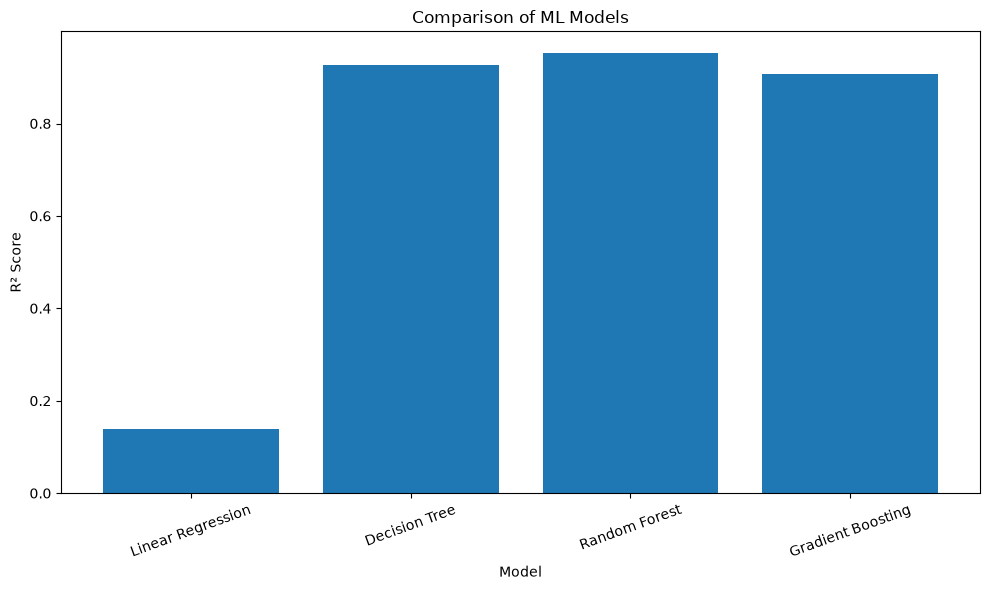

In [64]:
plt.figure(figsize=(10, 6))

plt.bar(comparison["Model"], comparison["R2"])

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Comparison of ML Models")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [65]:
new_data = pd.DataFrame({
    "Store": [1],
    "Holiday_Flag": [0],
    "Temperature": [70],
    "Fuel_Price": [3.0],
    "CPI": [220],
    "Unemployment": [8.0],
    "Year": [2012],
    "Month": [1],
    "Week": [5],
    "Time_Index": [len(df)]
})

In [66]:
rf_prediction = rf_model.predict(new_data)

print("Predicted Weekly Sales:", rf_prediction[0])

Predicted Weekly Sales: 1526339.2447000009


In [67]:
import joblib

joblib.dump(rf_model, "walmart_random_forest_model.pkl")

print("Model saved successfully!")

Model saved successfully!
